# Hypothesis 1: Does elevation affect teams differently?

**Hypothesis:** Elevation affects teams differently. Some teams should be relatively quicker at high altitude and others relatively slower, because of how their cars are set up (downforce and cooling).

**Analysis (from Phase 2 preregistration):**
- Linear regression with `q1_relative_pace` as the outcome
- Predictors: elevation, team, and elevation × team interactions
- Ferrari is the reference team
- F-test for whether the interactions are jointly significant
- Rerun without Mexico City (the only really high track)

We exclude wet Q1 sessions (`wet_q1 == True`), as noted in the cleaning notebook.

## Load data and make the analysis sample

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

df = pd.read_csv("../analysis_ready.csv")

# wet_q1 sometimes comes in as strings, so clean that up
df["wet_q1"] = df["wet_q1"].map({True: True, False: False, "True": True, "False": False})

print(df.shape)
print(df["wet_q1"].value_counts(dropna=False))

(878, 34)
wet_q1
False    778
True      90
NaN       10
Name: count, dtype: int64


In [2]:
# drop missing values needed for the regression, then keep only dry Q1 sessions
df = df.dropna(subset=["q1_relative_pace", "elevation_m", "team_id", "wet_q1", "is_mexico_city"])
dry = df[df["wet_q1"] == False].copy()

print("rows in dry sample:", len(dry))
print("sessions:", dry["session_key"].nunique())
print("teams:", dry["team_id"].nunique())
print("Mexico City rows:", dry["is_mexico_city"].sum())
dry[["q1_relative_pace", "elevation_m"]].describe()

rows in dry sample: 778
sessions: 78
teams: 10
Mexico City rows: 30


,q1_relative_pace,elevation_m
count,778.000000,778.000000
mean,-0.042890,252.455013
std,0.351741,471.097668
min,-1.056326,-15.000000
25%,-0.267231,5.000000
50%,-0.078196,40.000000
75%,0.156582,200.000000
max,1.603655,2238.000000


Quick look at relative pace vs elevation. Mexico City is way higher than everything else, which is why we also run the model without it.

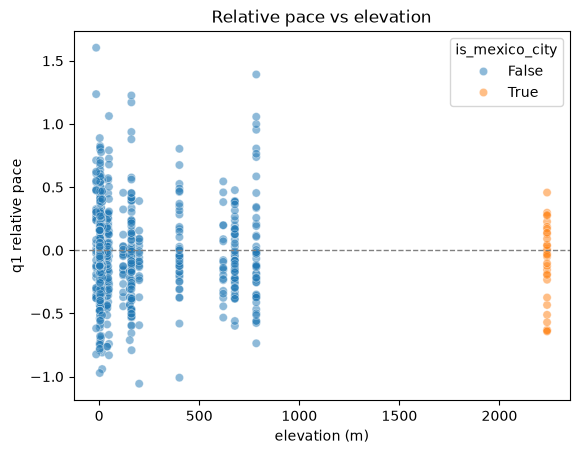

In [3]:
sns.scatterplot(data=dry, x="elevation_m", y="q1_relative_pace", hue="is_mexico_city", alpha=0.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.xlabel("elevation (m)")
plt.ylabel("q1 relative pace")
plt.title("Relative pace vs elevation")
plt.show()

## Main regression (all dry Q1 sessions)

Negative relative pace = better than usual for that team.  
The elevation × team terms say how much a team's elevation effect differs from Ferrari's.

In [4]:
# full model with interactions
model_full = smf.ols(
    "q1_relative_pace ~ elevation_m * C(team_id, Treatment(reference='ferrari'))",
    data=dry
).fit()

# reduced model without interactions (for the F-test)
model_reduced = smf.ols(
    "q1_relative_pace ~ elevation_m + C(team_id, Treatment(reference='ferrari'))",
    data=dry
).fit()

print(model_full.summary())

                            OLS Regression Results                            
Dep. Variable:       q1_relative_pace   R-squared:                       0.023
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.9225
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.555
Time:                        13:47:59   Log-Likelihood:                -281.64
No. Observations:                 778   AIC:                             603.3
Df Residuals:                     758   BIC:                             696.4
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                                                                             coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

In [5]:
# joint F-test: are the elevation x team interactions all zero?
ftest = anova_lm(model_reduced, model_full)
print(ftest)

print("\nF-test p-value:", ftest.iloc[1]["Pr(>F)"])
print("R-squared:", model_full.rsquared)

   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0     767.0  95.520925      0.0       NaN       NaN       NaN
1     758.0  93.958840      9.0  1.562085  1.400212  0.183754

F-test p-value: 0.183754066754549
R-squared: 0.0226016443622985


In [6]:
# look at just the interaction coefficients and their p-values
interaction_names = [name for name in model_full.params.index if "elevation_m:" in name]

interactions = pd.DataFrame({
    "coef": model_full.params[interaction_names],
    "pvalue": model_full.pvalues[interaction_names]
})
interactions

,coef,pvalue
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.alpine]",-0.000002,0.989338
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.aston_martin]",0.000169,0.159756
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.haas]",-0.000069,0.567803
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.mclaren]",-0.000095,0.428835
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.mercedes]",0.000117,0.330387
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.racing_bulls]",-0.000109,0.365242
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.red_bull]",0.000137,0.254747
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.sauber]",-0.000068,0.572592
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.williams]",0.000031,0.795706


## Rerun without Mexico City

Same model, but drop Mexico City so one high track isn't driving the result.

In [7]:
dry_no_mex = dry[dry["is_mexico_city"] == False].copy()
print("rows without Mexico City:", len(dry_no_mex))
print("sessions:", dry_no_mex["session_key"].nunique())

model_full_nm = smf.ols(
    "q1_relative_pace ~ elevation_m * C(team_id, Treatment(reference='ferrari'))",
    data=dry_no_mex
).fit()

model_reduced_nm = smf.ols(
    "q1_relative_pace ~ elevation_m + C(team_id, Treatment(reference='ferrari'))",
    data=dry_no_mex
).fit()

ftest_nm = anova_lm(model_reduced_nm, model_full_nm)
print(ftest_nm)
print("\nF-test p-value (no Mexico):", ftest_nm.iloc[1]["Pr(>F)"])
print("R-squared (no Mexico):", model_full_nm.rsquared)

rows without Mexico City: 748
sessions: 75


   df_resid        ssr  df_diff   ss_diff         F    Pr(>F)
0     737.0  92.863619      0.0       NaN       NaN       NaN
1     728.0  91.289847      9.0  1.573773  1.394467  0.186418

F-test p-value (no Mexico): 0.1864182094645811
R-squared (no Mexico): 0.022329080492795472


In [8]:
interaction_names_nm = [name for name in model_full_nm.params.index if "elevation_m:" in name]

interactions_nm = pd.DataFrame({
    "coef": model_full_nm.params[interaction_names_nm],
    "pvalue": model_full_nm.pvalues[interaction_names_nm]
})
interactions_nm

,coef,pvalue
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.alpine]",-0.000293,0.193571
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.aston_martin]",0.000191,0.396078
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.haas]",-0.000254,0.258692
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.mclaren]",-0.000247,0.272362
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.mercedes]",0.000062,0.782043
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.racing_bulls]",-0.000055,0.807914
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.red_bull]",0.000267,0.236182
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.sauber]",-0.000081,0.718945
"elevation_m:C(team_id, Treatment(reference='ferrari'))[T.williams]",0.000019,0.931567


## Interpretation

**Summarize:**  
In the main model (778 rows, dry Q1 only), the F-test for the elevation × team interactions has p ≈ 0.18. That is above 0.05, so the interactions are not jointly significant. None of the individual team interactions are significant either. R² is only about 0.02, so the model doesn't explain much.

**Predict:**  
Based on this, we wouldn't really expect clear team-specific elevation advantages/disadvantages relative to Ferrari in Q1.

**Outliers / oddities:**  
Mexico City is much higher than the other tracks, but dropping it barely changes the F-test (p still ≈ 0.19). So Mexico isn't the whole story. Also, rows in the same session aren't fully independent (same weather/track), which is a limitation, but since our p-values are already not significant it doesn't change the conclusion here.

**Decision:**  
At α = 0.05, we **fail to reject** Hypothesis 1's null (no team-specific elevation effects) for both the full dry sample and the no-Mexico sample. We don't find statistically significant evidence that elevation affects teams differently.